In [125]:
# Import tools for data analysis and model evaluation.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    make_scorer
)

In [126]:
# Load and preview the credit card dataset.
df = pd.read_csv('creditcard.csv')

df = df.head(80000)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [127]:
# Display dataset dimensions.
df.shape

(80000, 31)

In [128]:
# Summarize dataset columns and types.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    80000 non-null  float64
 1   V1      80000 non-null  float64
 2   V2      80000 non-null  float64
 3   V3      80000 non-null  float64
 4   V4      80000 non-null  float64
 5   V5      80000 non-null  float64
 6   V6      80000 non-null  float64
 7   V7      80000 non-null  float64
 8   V8      80000 non-null  float64
 9   V9      80000 non-null  float64
 10  V10     80000 non-null  float64
 11  V11     80000 non-null  float64
 12  V12     80000 non-null  float64
 13  V13     80000 non-null  float64
 14  V14     80000 non-null  float64
 15  V15     80000 non-null  float64
 16  V16     80000 non-null  float64
 17  V17     80000 non-null  float64
 18  V18     80000 non-null  float64
 19  V19     80000 non-null  float64
 20  V20     80000 non-null  float64
 21  V21     80000 non-null  float64
 22  V22     8

In [129]:
# Summarize numeric columns statistically.
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,...,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000
mean,37332.183588,-0.258086,-0.036364,0.678340,0.163600,-0.276254,0.095376,-0.114390,0.053252,-0.010000,...,-0.029000,-0.105751,-0.037651,0.007894,0.134427,0.026336,0.002025,0.002570,97.775498,0.002450
std,15209.718131,1.888947,1.679465,1.386402,1.368678,1.382928,1.305057,1.247498,1.233289,1.144390,...,0.739825,0.636423,0.628525,0.595679,0.440853,0.498120,0.390666,0.331055,269.180362,0.049437
min,0.000000,-56.407510,-72.715728,-33.680984,-5.172595,-42.147898,-26.160506,-31.764946,-73.216718,-9.283925,...,-34.830382,-10.933144,-26.751119,-2.836627,-7.495741,-2.534330,-9.390980,-9.617915,0.000000,0.000000
25%,30718.500000,-1.019388,-0.599350,0.186697,-0.725926,-0.894690,-0.642417,-0.604450,-0.141200,-0.686546,...,-0.224356,-0.524838,-0.178315,-0.322913,-0.129354,-0.326741,-0.063341,-0.005819,7.680000,0.000000
50%,40052.000000,-0.250144,0.069013,0.765189,0.182134,-0.309687,-0.153999,-0.073816,0.069079,-0.089189,...,-0.058577,-0.080453,-0.050284,0.064108,0.172777,-0.072778,0.009277,0.022868,26.955000,0.000000
75%,49105.000000,1.153620,0.721751,1.394244,1.043840,0.258717,0.490107,0.416536,0.349036,0.624249,...,0.117690,0.309546,0.080590,0.405444,0.421519,0.307898,0.082446,0.076056,89.205000,0.000000
max,58287.000000,1.960497,18.902453,4.226108,16.715537,34.801666,22.529298,36.677268,20.007208,10.392889,...,22.614889,10.503090,18.946734,4.014444,5.525093,3.517346,12.152401,33.847808,19656.530000,1.000000


In [130]:
# Count missing values in each column.
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [131]:
# Count transactions by class.
df['Class'].value_counts()

Class
0    79804
1      196
Name: count, dtype: int64

In [132]:
# Count class labels with Counter.
Counter(df['Class'])

Counter({0: 79804, 1: 196})

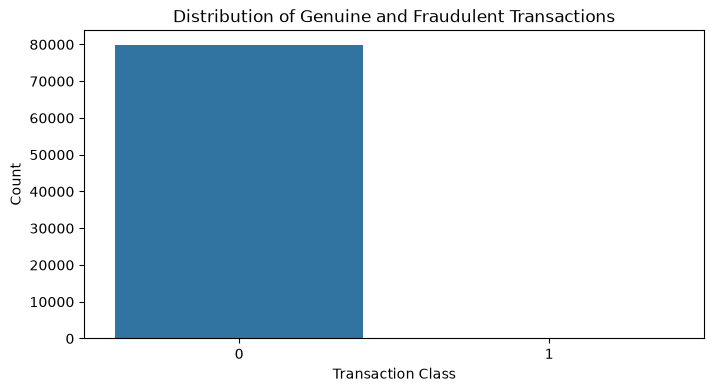

In [133]:
# Plot genuine and fraudulent transaction counts.
plt.figure(figsize=(8, 4))

sns.countplot(data=df, x='Class')

plt.title('Distribution of Genuine and Fraudulent Transactions')
plt.xlabel('Transaction Class')
plt.ylabel('Count')

plt.show()

In [134]:
# Separate model features and target labels.
X = df.drop(columns=['Time', 'Amount', 'Class'])

y = df['Class']

In [135]:
# Split data while preserving class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [136]:
# Display training feature dimensions.
X_train.shape

(64000, 28)

In [137]:
# Display testing feature dimensions.
X_test.shape

(16000, 28)

In [138]:
# Count labels in the training set.
Counter(y_train)

Counter({0: 63843, 1: 157})

In [139]:
# Count labels in the testing set.
Counter(y_test)

Counter({0: 15961, 1: 39})

In [140]:
# Fit class-weighted logistic regression.
model = LogisticRegression(
    max_iter=1000,
    class_weight={0: 1, 1: 2}
)

model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*","{0: 1, 1: 2}"
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. De

In [141]:
# Predict test transaction classes.
y_pred = model.predict(X_test)

In [142]:
# Calculate classification performance metrics.
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred, zero_division=0))

print("Recall:", recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

Accuracy: 0.999
Precision: 0.7948717948717948
Recall: 0.7948717948717948
F1 Score: 0.7948717948717948


In [143]:
# Print detailed classification metrics.
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     15961
           1       0.79      0.79      0.79        39

    accuracy                           1.00     16000
   macro avg       0.90      0.90      0.90     16000
weighted avg       1.00      1.00      1.00     16000



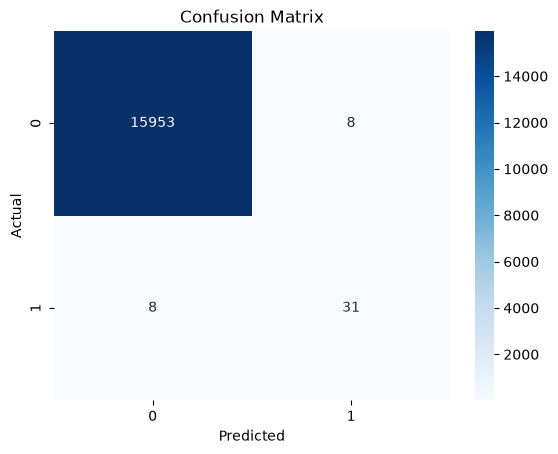

In [144]:
# Plot the logistic regression confusion matrix.
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.show()

In [145]:
# Import tools for parameter search and scoring.
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_score, recall_score, make_scorer

In [146]:
# Define positive-class weights to evaluate.
param_grid = {
    'class_weight': [
        {0: 1, 1: v}
        for v in np.linspace(1, 20, 30)
    ]
}

In [147]:
# Configure cross-validation for class-weight selection.
grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000),
    param_grid=param_grid,
    scoring={
        'precision': make_scorer(precision_score),
        'recall': make_scorer(recall_score)
    },
    refit='precision',
    return_train_score=True,
    cv=10,
    n_jobs=-1
)

In [148]:
# Search class weights using training data.
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=1000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [{0: 1, 1: np.float64(1.0)}, {0: 1, 1: np.float64(1.6551724137931034)}, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'precision': make_scorer(p...hod='predict'), 'recall': make_scorer(r...hod='predict')}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` d

In [149]:
# Display best weight and precision score.
print("Best Parameters:", grid.best_params_)

print("Best Precision Score:", grid.best_score_)

Best Parameters: {'class_weight': {0: 1, 1: np.float64(5.586206896551724)}}
Best Precision Score: 0.8262159924698624


In [150]:
# Convert search results into a dataframe.
df_results = pd.DataFrame(grid.cv_results_)

df_results.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,params,split0_test_precision,split1_test_precision,split2_test_precision,split3_test_precision,...,split2_train_recall,split3_train_recall,split4_train_recall,split5_train_recall,split6_train_recall,split7_train_recall,split8_train_recall,split9_train_recall,mean_train_recall,std_train_recall
0,0.210397,0.028846,0.007079,0.001668,"{0: 1, 1: 1.0}","{'class_weight': {0: 1, 1: 1.0}}",0.750000,0.692308,0.785714,0.833333,...,0.570423,0.574468,0.602837,0.581560,0.617021,0.624113,0.588652,0.553191,0.589537,0.020525
1,0.138110,0.016993,0.009416,0.003186,"{0: 1, 1: 1.6551724137931034}","{'class_weight': {0: 1, 1: 1.6551724137931034}}",0.750000,0.666667,0.812500,0.846154,...,0.633803,0.638298,0.666667,0.666667,0.666667,0.702128,0.666667,0.624113,0.658895,0.021195
2,0.141641,0.012850,0.008815,0.003424,"{0: 1, 1: 2.310344827586207}","{'class_weight': {0: 1, 1: 2.310344827586207}}",0.750000,0.733333,0.812500,0.866667,...,0.704225,0.687943,0.716312,0.695035,0.737589,0.751773,0.695035,0.673759,0.707717,0.021932
3,0.132723,0.010300,0.007422,0.001969,"{0: 1, 1: 2.9655172413793105}","{'class_weight': {0: 1, 1: 2.9655172413793105}}",0.769231,0.733333,0.812500,0.875000,...,0.718310,0.723404,0.751773,0.716312,0.765957,0.815603,0.730496,0.716312,0.741000,0.029214
4,0.131475,0.021083,0.006509,0.001450,"{0: 1, 1: 3.6206896551724137}","{'class_weight': {0: 1, 1: 3.6206896551724137}}",0.812500,0.764706,0.823529,0.875000,...,0.753521,0.758865,0.765957,0.744681,0.787234,0.836879,0.773050,0.758865,0.770722,0.024588


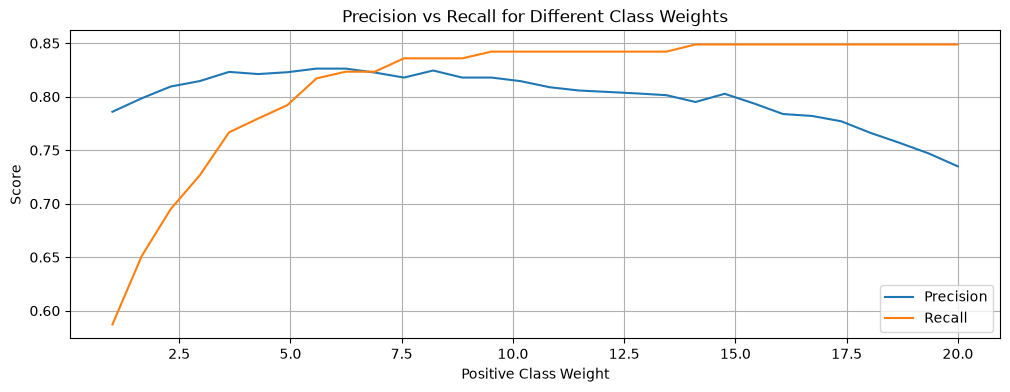

In [151]:
# Plot precision and recall across class weights.
weights = [
    item[1]
    for item in df_results['param_class_weight']
]

plt.figure(figsize=(12, 4))

plt.plot(
    weights,
    df_results['mean_test_precision'],
    label='Precision'
)

plt.plot(
    weights,
    df_results['mean_test_recall'],
    label='Recall'
)

plt.xlabel('Positive Class Weight')
plt.ylabel('Score')
plt.title('Precision vs Recall for Different Class Weights')

plt.legend()
plt.grid(True)

plt.show()

In [152]:
# Score models by their lower precision or recall.
def min_recall_precision(y_true, y_pred):
    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    return min(recall, precision)

In [153]:
# Search weights using balanced precision and recall.
grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000),

    param_grid={
        'class_weight': [
            {0: 1, 1: v}
            for v in np.linspace(1, 20, 30)
        ]
    },

    scoring={
        'precision': make_scorer(
            precision_score,
            zero_division=0
        ),

        'recall': make_scorer(
            recall_score,
            zero_division=0
        ),

        'min_both': make_scorer(
            min_recall_precision
        )
    },

    refit='min_both',
    return_train_score=True,
    cv=10,
    n_jobs=-1
)

In [154]:
# Fit the balanced scoring search.
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=1000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [{0: 1, 1: np.float64(1.0)}, {0: 1, 1: np.float64(1.6551724137931034)}, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'min_both': make_scorer(m...hod='predict'), 'precision': make_scorer(p...ro_division=0), 'recall': make_scorer(r...ro_division=0)}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'min_both'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be 

In [155]:
# Display best parameters and balanced score.
print("Best Parameters:", grid.best_params_)

print("Best Minimum Precision/Recall:", grid.best_score_)

Best Parameters: {'class_weight': {0: 1, 1: np.float64(9.517241379310345)}}
Best Minimum Precision/Recall: 0.7757598039215685


In [156]:
# Convert balanced search results into a dataframe.
df_results = pd.DataFrame(grid.cv_results_)

df_results.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,params,split0_test_precision,split1_test_precision,split2_test_precision,split3_test_precision,...,split2_train_min_both,split3_train_min_both,split4_train_min_both,split5_train_min_both,split6_train_min_both,split7_train_min_both,split8_train_min_both,split9_train_min_both,mean_train_min_both,std_train_min_both
0,0.115588,0.020172,0.011132,0.003906,"{0: 1, 1: 1.0}","{'class_weight': {0: 1, 1: 1.0}}",0.750000,0.692308,0.785714,0.833333,...,0.570423,0.574468,0.602837,0.581560,0.617021,0.624113,0.588652,0.553191,0.589537,0.020525
1,0.119713,0.015379,0.012343,0.003322,"{0: 1, 1: 1.6551724137931034}","{'class_weight': {0: 1, 1: 1.6551724137931034}}",0.750000,0.666667,0.812500,0.846154,...,0.633803,0.638298,0.666667,0.666667,0.666667,0.702128,0.666667,0.624113,0.658895,0.021195
2,0.122581,0.018877,0.009868,0.002712,"{0: 1, 1: 2.310344827586207}","{'class_weight': {0: 1, 1: 2.310344827586207}}",0.750000,0.733333,0.812500,0.866667,...,0.704225,0.687943,0.716312,0.695035,0.737589,0.751773,0.695035,0.673759,0.707717,0.021932
3,0.119142,0.014967,0.013641,0.003187,"{0: 1, 1: 2.9655172413793105}","{'class_weight': {0: 1, 1: 2.9655172413793105}}",0.769231,0.733333,0.812500,0.875000,...,0.718310,0.723404,0.751773,0.716312,0.765957,0.815603,0.730496,0.716312,0.741000,0.029214
4,0.127738,0.029409,0.012506,0.002781,"{0: 1, 1: 3.6206896551724137}","{'class_weight': {0: 1, 1: 3.6206896551724137}}",0.812500,0.764706,0.823529,0.875000,...,0.753521,0.758865,0.765957,0.744681,0.787234,0.836879,0.773050,0.758865,0.770722,0.024588


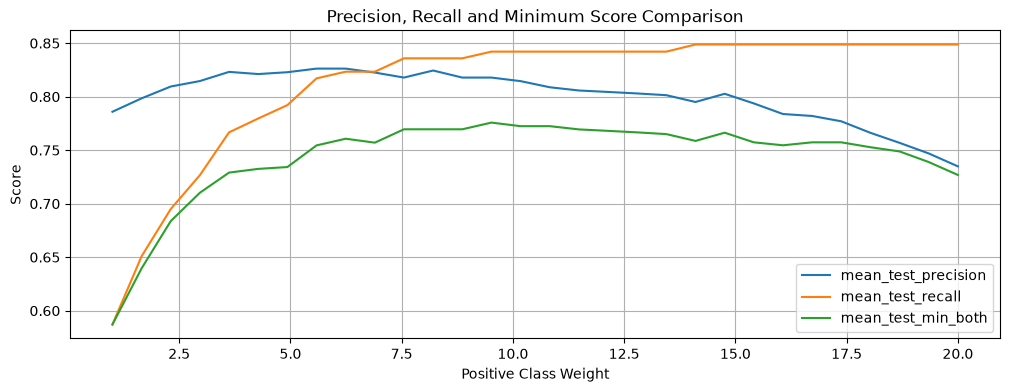

In [157]:
# Compare precision, recall, and minimum scores.
weights = [
    item[1]
    for item in df_results['param_class_weight']
]

plt.figure(figsize=(12, 4))

for score in [
    'mean_test_precision',
    'mean_test_recall',
    'mean_test_min_both'
]:

    plt.plot(
        weights,
        df_results[score],
        label=score
    )

plt.xlabel('Positive Class Weight')
plt.ylabel('Score')

plt.title('Precision, Recall and Minimum Score Comparison')

plt.legend()
plt.grid(True)

plt.show()

In [158]:
# Weight training samples by transaction amount.
sample_weights = np.log1p(
    df.loc[X_train.index, 'Amount']
)

In [159]:
# Configure weighted balanced model selection.
grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000),

    param_grid={
        'class_weight': [
            {0: 1, 1: v}
            for v in np.linspace(1, 20, 30)
        ]
    },

    scoring={
        'precision': make_scorer(
            precision_score,
            zero_division=0
        ),

        'recall': make_scorer(
            recall_score,
            zero_division=0
        ),

        'min_both': make_scorer(
            min_recall_precision
        )
    },

    refit='min_both',
    return_train_score=True,
    cv=10,
    n_jobs=-1
)

In [160]:
# Fit the search using sample weights.
grid.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

/opt/homebrew/Caskroom/miniforge/base/envs/ai/lib/python3.12/site-packages/sklearn/model_selection/_search.py:908: UserWarning: The scoring min_both=make_scorer(min_recall_precision, response_method='predict') does not support sample_weight, which may lead to statistically incorrect results when fitting GridSearchCV(cv=10, estimator=LogisticRegression(max_iter=1000), n_jobs=-1,
             param_grid={'class_weight': [{0: 1, 1: np.float64(1.0)},
                                          {0: 1,
                                           1: np.float64(1.6551724137931034)},
                                          {0: 1,
                                           1: np.float64(2.310344827586207)},
                                          {0: 1,
                                           1: np.float64(2.9655172413793105)},
                                          {0: 1,
                                           1: np.float64(3.6206896551724137)},
                                      

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=1000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [{0: 1, 1: np.float64(1.0)}, {0: 1, 1: np.float64(1.6551724137931034)}, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'min_both': make_scorer(m...hod='predict'), 'precision': make_scorer(p...ro_division=0), 'recall': make_scorer(r...ro_division=0)}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'min_both'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be 

In [161]:
# Display best parameters and weighted score.
print("Best Parameters:", grid.best_params_)

print("Best Score:", grid.best_score_)

Best Parameters: {'class_weight': {0: 1, 1: np.float64(8.206896551724139)}}
Best Score: 0.7372235122119023


In [162]:
# Convert weighted search results into a dataframe.
df_results = pd.DataFrame(grid.cv_results_)

df_results.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_class_weight,params,split0_test_precision,split1_test_precision,split2_test_precision,split3_test_precision,...,split2_train_min_both,split3_train_min_both,split4_train_min_both,split5_train_min_both,split6_train_min_both,split7_train_min_both,split8_train_min_both,split9_train_min_both,mean_train_min_both,std_train_min_both
0,0.137166,0.027995,0.013188,0.003737,"{0: 1, 1: 1.0}","{'class_weight': {0: 1, 1: 1.0}}",0.846092,0.541277,0.836154,0.664363,...,0.570423,0.574468,0.560284,0.553191,0.581560,0.574468,0.553191,0.517730,0.559799,0.017024
1,0.139807,0.017619,0.016301,0.005913,"{0: 1, 1: 1.6551724137931034}","{'class_weight': {0: 1, 1: 1.6551724137931034}}",0.746503,0.511086,0.854776,0.687352,...,0.591549,0.595745,0.602837,0.609929,0.617021,0.624113,0.609929,0.567376,0.602273,0.014874
2,0.143064,0.012446,0.015461,0.004757,"{0: 1, 1: 2.310344827586207}","{'class_weight': {0: 1, 1: 2.310344827586207}}",0.751007,0.511086,0.857213,0.813799,...,0.633803,0.645390,0.652482,0.638298,0.673759,0.709220,0.659574,0.617021,0.652532,0.023920
3,0.149742,0.014324,0.014195,0.004720,"{0: 1, 1: 2.9655172413793105}","{'class_weight': {0: 1, 1: 2.9655172413793105}}",0.755353,0.560514,0.857213,0.818305,...,0.683099,0.695035,0.680851,0.666667,0.744681,0.773050,0.702128,0.673759,0.704180,0.031453
4,0.140733,0.016806,0.014145,0.004477,"{0: 1, 1: 3.6206896551724137}","{'class_weight': {0: 1, 1: 3.6206896551724137}}",0.763606,0.560514,0.857213,0.844065,...,0.746479,0.744681,0.723404,0.709220,0.787234,0.822695,0.744681,0.744681,0.755829,0.030851


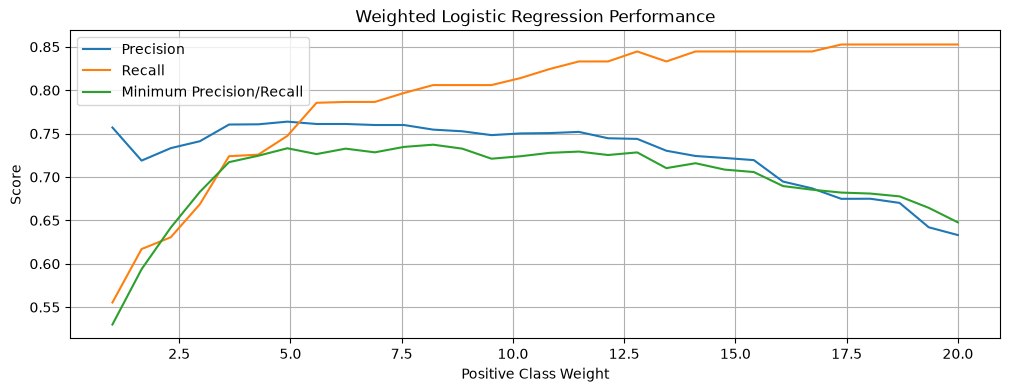

In [163]:
# Plot weighted model performance across class weights.
weights = [
    item[1]
    for item in df_results['param_class_weight']
]

plt.figure(figsize=(12, 4))

plt.plot(
    weights,
    df_results['mean_test_precision'],
    label='Precision'
)

plt.plot(
    weights,
    df_results['mean_test_recall'],
    label='Recall'
)

plt.plot(
    weights,
    df_results['mean_test_min_both'],
    label='Minimum Precision/Recall'
)

plt.xlabel('Positive Class Weight')
plt.ylabel('Score')

plt.title('Weighted Logistic Regression Performance')

plt.legend()
plt.grid(True)

plt.show()

In [164]:
# Import anomaly detection and counting tools.
from collections import Counter
from sklearn.ensemble import IsolationForest

In [165]:
# Fit Isolation Forest to transaction features.
mod = IsolationForest().fit(X)

In [166]:
# Convert anomaly predictions into binary labels.
np.where(
    mod.predict(X) == -1,
    1,
    0
)

array([0, 0, 0, ..., 0, 0, 0], shape=(80000,))

In [167]:
# Count predicted anomalies and genuine transactions.
predictions = np.where(
    mod.predict(X) == -1,
    1,
    0
)

Counter(predictions)

Counter({np.int64(0): 77234, np.int64(1): 2766})

In [168]:
# Calculate precision from anomaly predictions.
def outlier_precision(mod, X, y):
    preds = mod.predict(X)

    return precision_score(
        y,
        np.where(preds == -1, 1, 0)
    )

In [169]:
# Calculate recall from anomaly predictions.
def outlier_recall(mod, X, y):
    preds = mod.predict(X)

    return recall_score(
        y,
        np.where(preds == -1, 1, 0)
    )

In [170]:
# Configure Isolation Forest contamination search.
grid = GridSearchCV(
    estimator=IsolationForest(),

    param_grid={
        'contamination': np.linspace(
            0.001,
            0.02,
            10
        )
    },

    scoring={
        'precision': outlier_precision,
        'recall': outlier_recall
    },

    refit='precision',
    cv=5,
    n_jobs=-1
)

In [171]:
# Search contamination values using labeled data.
grid.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",IsolationForest()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'contamination': array([0.001 ..., 0.02 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'precision': <function out...t 0x14e0c93a0>, 'recall': <function out...t 0x14e0c9580>}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbos

In [172]:
# Display best contamination and precision score.
print("Best Parameters:", grid.best_params_)

print("Best Precision:", grid.best_score_)

Best Parameters: {'contamination': np.float64(0.001)}
Best Precision: 0.29398023360287506


In [173]:
# Convert anomaly search results into a dataframe.
df_results = pd.DataFrame(grid.cv_results_)

df_results.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_contamination,params,split0_test_precision,split1_test_precision,split2_test_precision,split3_test_precision,...,std_test_precision,rank_test_precision,split0_test_recall,split1_test_recall,split2_test_recall,split3_test_recall,split4_test_recall,mean_test_recall,std_test_recall,rank_test_recall
0,0.506277,0.019883,0.143874,0.006105,0.001000,{'contamination': 0.001},0.660377,0.000000,0.809524,0.000000,...,0.363127,1,0.479452,0.000000,0.377778,0.000000,0.000000,0.171446,0.212425,10
1,0.483770,0.020859,0.159330,0.013175,0.003111,{'contamination': 0.003111111111111111},0.402174,0.295455,0.547170,0.000000,...,0.193490,2,0.506849,0.448276,0.644444,0.000000,0.200000,0.359914,0.230420,9
2,0.474051,0.017665,0.175103,0.007428,0.005222,{'contamination': 0.005222222222222222},0.353741,0.153846,0.344828,0.039216,...,0.122803,3,0.712329,0.482759,0.666667,0.105263,0.400000,0.473403,0.216997,8
3,0.479492,0.028718,0.173890,0.012645,0.007333,{'contamination': 0.007333333333333333},0.322981,0.116667,0.321739,0.041667,...,0.121111,4,0.712329,0.482759,0.822222,0.157895,0.366667,0.508374,0.238189,7
4,0.500147,0.027532,0.165311,0.011305,0.009444,{'contamination': 0.009444444444444443},0.264423,0.133758,0.243750,0.031915,...,0.092216,5,0.753425,0.724138,0.866667,0.157895,0.400000,0.580425,0.262146,6


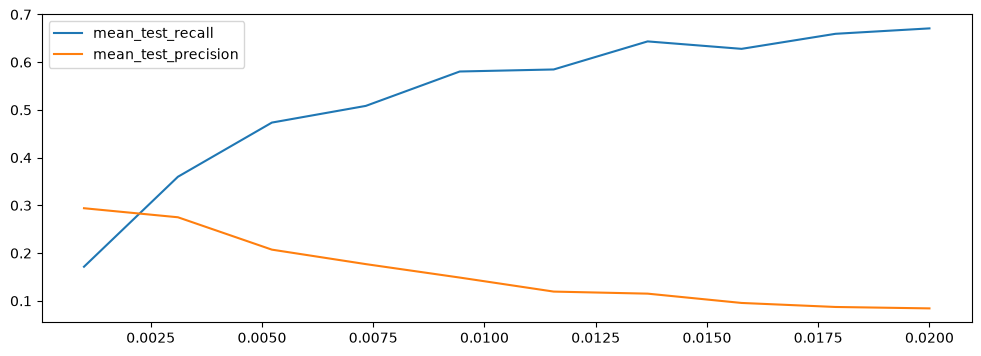

In [174]:
# Plot precision and recall by contamination.
plt.figure(figsize=(12, 4))

df_results = pd.DataFrame(grid.cv_results_)

for score in [
    'mean_test_recall',
    'mean_test_precision'
]:

    plt.plot(
        df_results['param_contamination'],
        df_results[score],
        label=score
    )

plt.legend()

plt.show()

In [175]:
# Store the best estimator from the current search.
best_logistic = grid.best_estimator_

In [176]:
# Store the best estimator from the current search.
best_logistic = grid.best_estimator_

In [177]:
# Fit Isolation Forest with selected contamination.
best_isolation = IsolationForest(
    contamination=grid.best_params_['contamination'],
    random_state=42
)

best_isolation.fit(X_train)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",np.float64(0.001)
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [178]:
# Predict test classes with the selected model.
logistic_pred = best_logistic.predict(X_test)

In [179]:
# Convert Isolation Forest predictions into binary labels.
isolation_pred = np.where(
    best_isolation.predict(X_test) == -1,
    1,
    0
)

In [182]:
# Correct labels and inspect logistic predictions.

logistic_pred = np.where(logistic_pred == -1, 0, 1)

print("Corrected Logistic Predictions:")
print("Unique values:", np.unique(logistic_pred))

Corrected Logistic Predictions:
Unique values: [0 1]


In [183]:
# Compare model precision, recall, and F1 scores.
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Isolation Forest'
    ],

    'Precision': [
        precision_score(y_test, logistic_pred, zero_division=0),
        precision_score(y_test, isolation_pred, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, logistic_pred, zero_division=0),
        recall_score(y_test, isolation_pred, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, logistic_pred, zero_division=0),
        f1_score(y_test, isolation_pred, zero_division=0)
    ]
})

comparison

,Model,Precision,Recall,F1 Score
0,Logistic Regression,0.002002,0.820513,0.003995
1,Isolation Forest,0.481481,0.333333,0.393939


In [184]:
# Compare label ranges and confusion matrices.
print("Training target labels:", np.unique(y_train))
print("Testing target labels:", np.unique(y_test))

from sklearn.metrics import confusion_matrix

print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, logistic_pred))

print("\nIsolation Forest Confusion Matrix:")
print(confusion_matrix(y_test, isolation_pred))

Training target labels: [0 1]
Testing target labels: [0 1]

Logistic Regression Confusion Matrix:
[[   12 15949]
 [    7    32]]

Isolation Forest Confusion Matrix:
[[15947    14]
 [   26    13]]


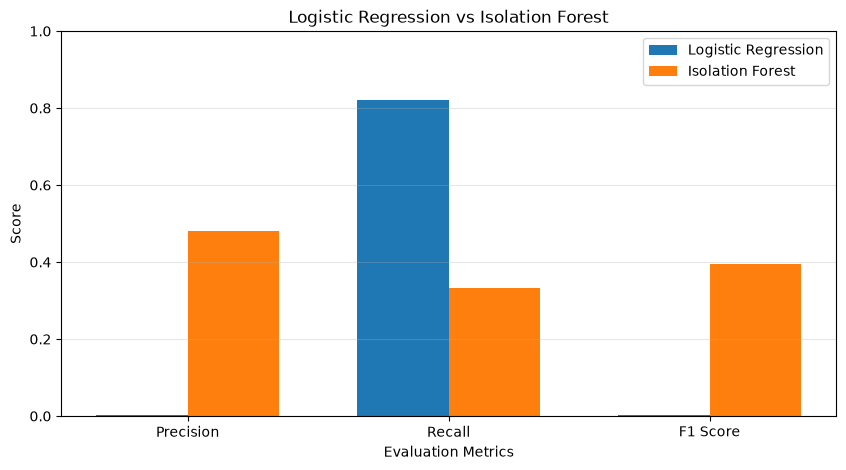

In [185]:
# Plot side-by-side model metric scores.
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Precision', 'Recall', 'F1 Score']

logistic_scores = comparison.iloc[0, 1:].values
isolation_scores = comparison.iloc[1, 1:].values

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    logistic_scores,
    width,
    label='Logistic Regression'
)

plt.bar(
    x + width/2,
    isolation_scores,
    width,
    label='Isolation Forest'
)

plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.title('Logistic Regression vs Isolation Forest')

plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

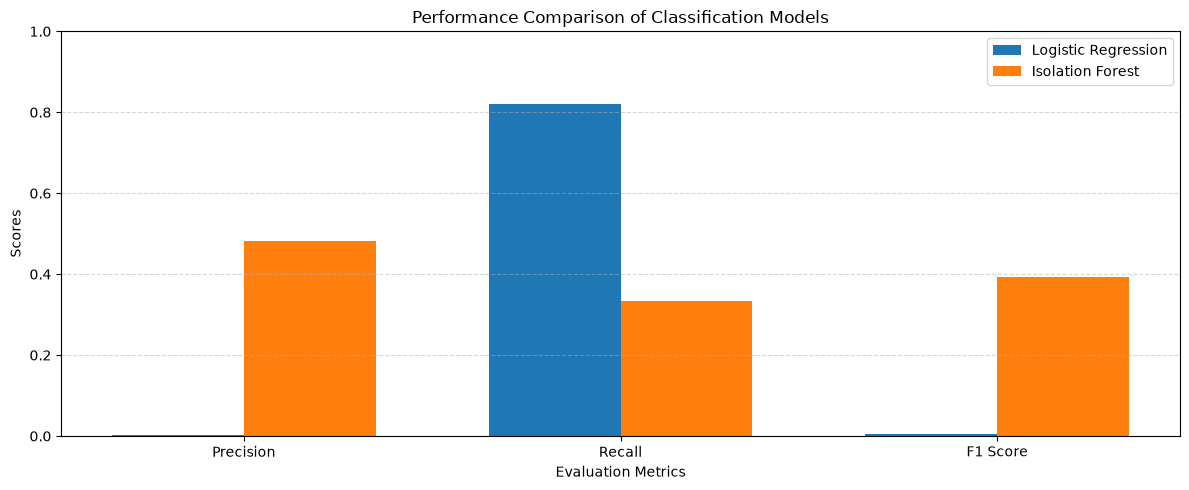

In [186]:
# Plot model performance across evaluation metrics.
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Precision', 'Recall', 'F1 Score']

logistic_scores = comparison.iloc[0, 1:].values
isolation_scores = comparison.iloc[1, 1:].values

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width/2,
    logistic_scores,
    width,
    label='Logistic Regression'
)

plt.bar(
    x + width/2,
    isolation_scores,
    width,
    label='Isolation Forest'
)

plt.xlabel('Evaluation Metrics')
plt.ylabel('Scores')
plt.title('Performance Comparison of Classification Models')

plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

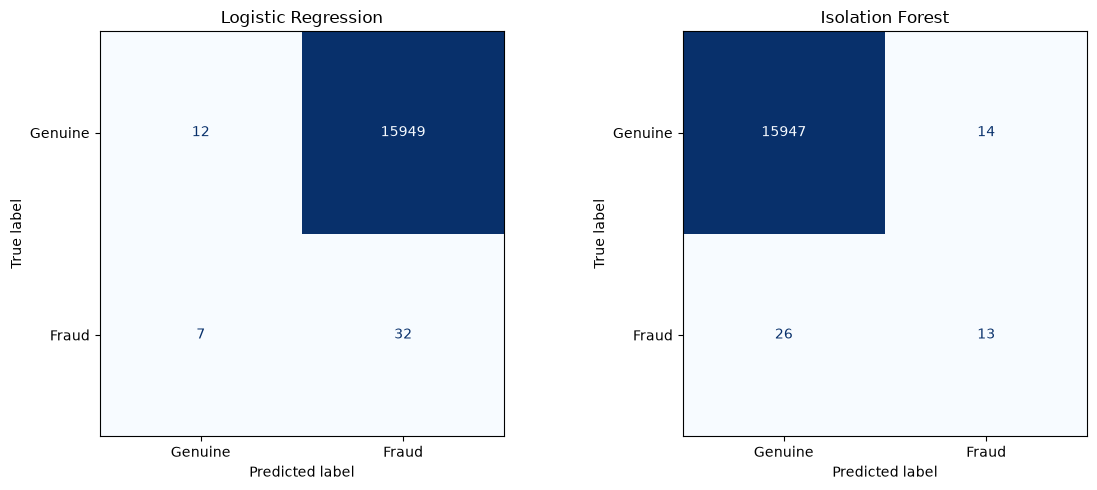

In [187]:
# Display confusion matrices for both models.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ('Logistic Regression', logistic_pred),
    ('Isolation Forest', isolation_pred)
]

for ax, (name, predictions) in zip(axes, models):

    cm = confusion_matrix(y_test, predictions)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Genuine', 'Fraud']
    )

    display.plot(
        ax=ax,
        cmap='Blues',
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

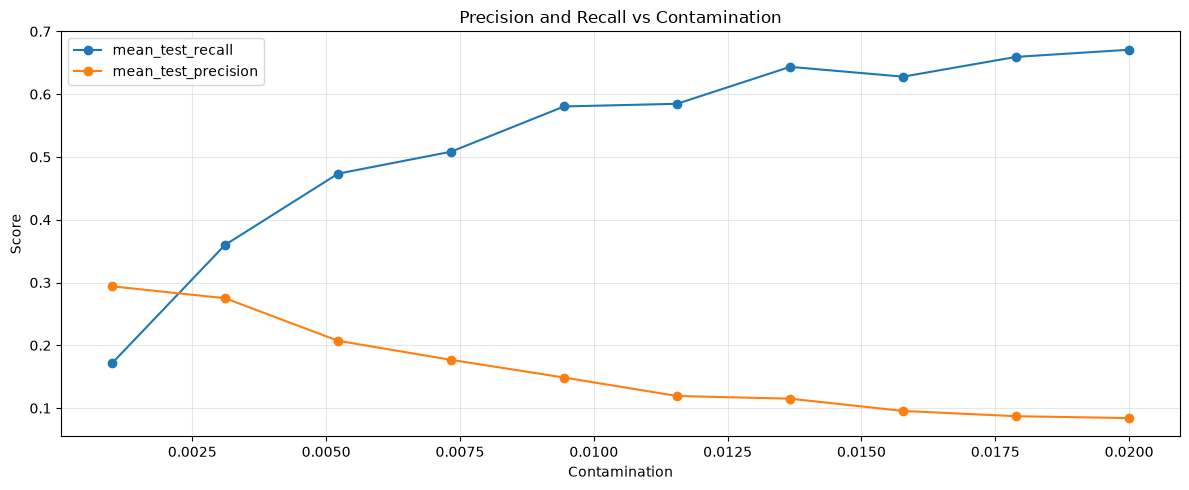

In [188]:
# Plot evaluation scores across contamination values.
plt.figure(figsize=(12, 5))

df_results = pd.DataFrame(grid.cv_results_)

for score in ['mean_test_recall', 'mean_test_precision']:

    plt.plot(
        df_results['param_contamination'].astype(float),
        df_results[score],
        marker='o',
        label=score
    )

plt.xlabel('Contamination')
plt.ylabel('Score')
plt.title('Precision and Recall vs Contamination')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [189]:
# Print model comparison and highest F1 model.
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 50)

print(comparison.to_string(index=False))

print("\nBest Model based on F1 Score:")

best_model = comparison.loc[
    comparison['F1 Score'].idxmax(), 'Model'
]

print(best_model)

FINAL MODEL PERFORMANCE COMPARISON
              Model  Precision   Recall  F1 Score
Logistic Regression   0.002002 0.820513  0.003995
   Isolation Forest   0.481481 0.333333  0.393939

Best Model based on F1 Score:
Isolation Forest


In [190]:
# Display training and testing label values.
print("Training labels:", np.unique(y_train))
print("Testing labels:", np.unique(y_test))

Training labels: [0 1]
Testing labels: [0 1]


In [191]:
# Inspect actual and predicted label values.
import numpy as np

print("Actual Test Labels:")
print(np.unique(y_test))

print("\nLogistic Regression Predictions:")
print(np.unique(logistic_pred))

print("\nIsolation Forest Predictions:")
print(np.unique(isolation_pred))

Actual Test Labels:
[0 1]

Logistic Regression Predictions:
[0 1]

Isolation Forest Predictions:
[0 1]


In [192]:
# Convert anomaly labels into binary fraud labels.
isolation_pred = np.where(isolation_pred == -1, 1, 0)

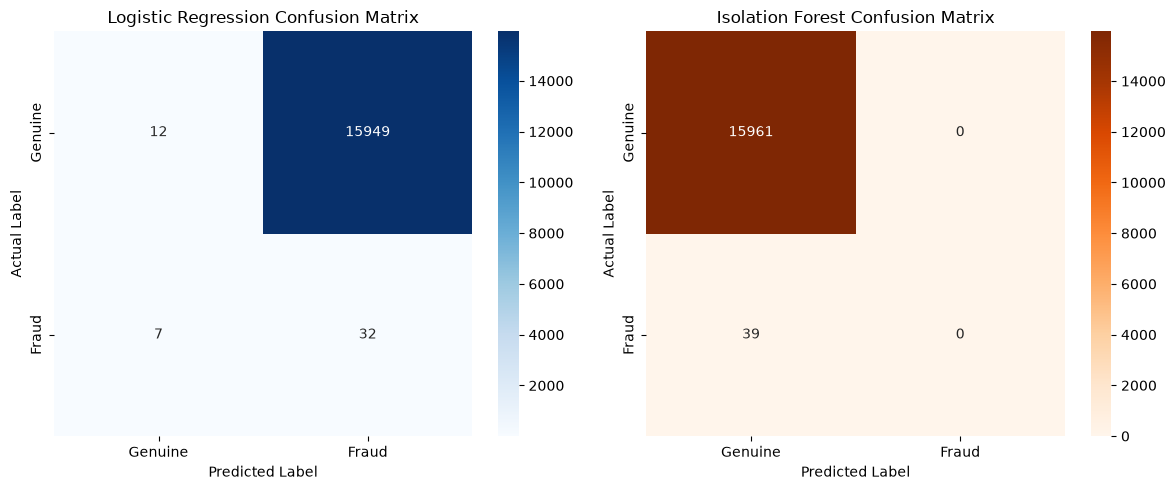

In [193]:
# Plot confusion matrices for both classifiers.
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrices
cm_logistic = confusion_matrix(y_test, logistic_pred)
cm_isolation = confusion_matrix(y_test, isolation_pred)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine', 'Fraud'],
    yticklabels=['Genuine', 'Fraud'],
    ax=axes[0]
)

axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

sns.heatmap(
    cm_isolation,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Genuine', 'Fraud'],
    yticklabels=['Genuine', 'Fraud'],
    ax=axes[1]
)

axes[1].set_title('Isolation Forest Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

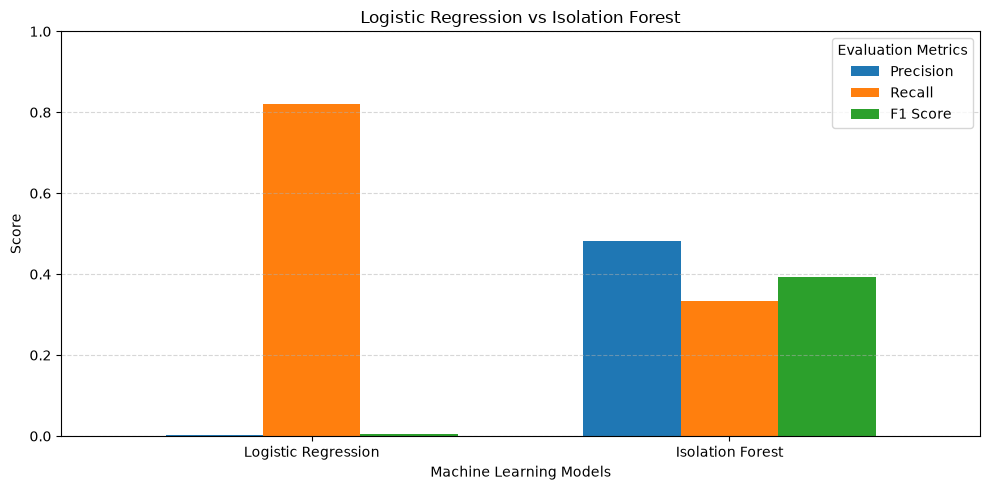

In [194]:
# Plot model scores across evaluation metrics.
comparison_plot = comparison.set_index('Model')[
    ['Precision', 'Recall', 'F1 Score']
]

comparison_plot.plot(
    kind='bar',
    figsize=(10, 5),
    width=0.7
)

plt.title('Logistic Regression vs Isolation Forest')
plt.xlabel('Machine Learning Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

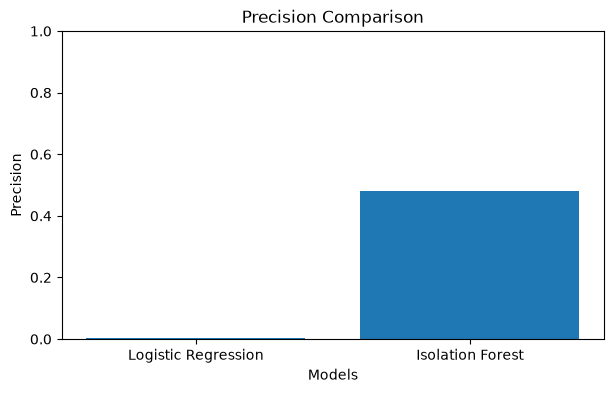

In [195]:
# Plot precision scores for each model.
plt.figure(figsize=(7, 4))

plt.bar(
    comparison['Model'],
    comparison['Precision']
)

plt.title('Precision Comparison')
plt.xlabel('Models')
plt.ylabel('Precision')
plt.ylim(0, 1)
plt.show()

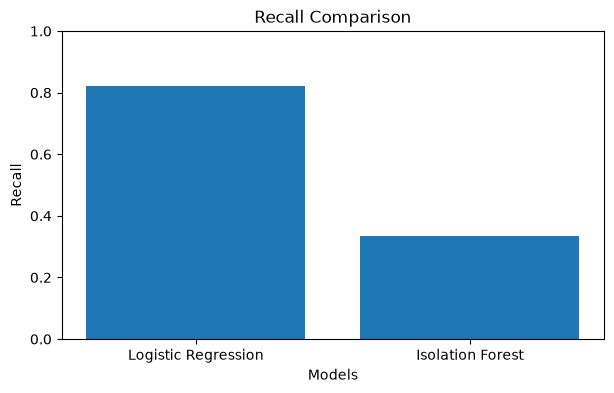

In [196]:
# Plot recall scores for each model.
plt.figure(figsize=(7, 4))

plt.bar(
    comparison['Model'],
    comparison['Recall']
)

plt.title('Recall Comparison')
plt.xlabel('Models')
plt.ylabel('Recall')
plt.ylim(0, 1)
plt.show()

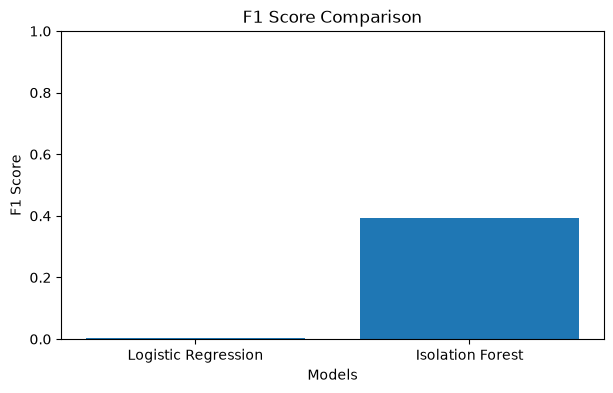

In [197]:
# Plot F1 scores for each model.
plt.figure(figsize=(7, 4))

plt.bar(
    comparison['Model'],
    comparison['F1 Score']
)

plt.title('F1 Score Comparison')
plt.xlabel('Models')
plt.ylabel('F1 Score')
plt.ylim(0, 1)
plt.show()

In [198]:
# Print classification reports for both models.
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION")
print(classification_report(
    y_test,
    logistic_pred,
    target_names=['Genuine', 'Fraud'],
    zero_division=0
))

print("\nISOLATION FOREST")
print(classification_report(
    y_test,
    isolation_pred,
    target_names=['Genuine', 'Fraud'],
    zero_division=0
))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

     Genuine       0.63      0.00      0.00     15961
       Fraud       0.00      0.82      0.00        39

    accuracy                           0.00     16000
   macro avg       0.32      0.41      0.00     16000
weighted avg       0.63      0.00      0.00     16000


ISOLATION FOREST
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     15961
       Fraud       0.00      0.00      0.00        39

    accuracy                           1.00     16000
   macro avg       0.50      0.50      0.50     16000
weighted avg       1.00      1.00      1.00     16000



In [201]:
# Display model scores and the highest F1 result.
from IPython.display import display as show_table

print("FINAL MODEL COMPARISON")

show_table(comparison)

best_model = comparison.loc[
    comparison['F1 Score'].idxmax()
]

print("\nBest Model:", best_model['Model'])
print("Precision:", best_model['Precision'])
print("Recall:", best_model['Recall'])
print("F1 Score:", best_model['F1 Score'])

FINAL MODEL COMPARISON


,Model,Precision,Recall,F1 Score
0,Logistic Regression,0.002002,0.820513,0.003995
1,Isolation Forest,0.481481,0.333333,0.393939



Best Model: Isolation Forest
Precision: 0.48148148148148145
Recall: 0.3333333333333333
F1 Score: 0.3939393939393939


In [202]:
# Compare actual labels with anomaly predictions.
print("Actual labels:", np.unique(y_test, return_counts=True))

print(
    "Isolation Forest predictions:",
    np.unique(isolation_pred, return_counts=True)
)

Actual labels: (array([0, 1]), array([15961,    39]))
Isolation Forest predictions: (array([0]), array([16000]))


In [206]:
# Search Isolation Forest contamination on training data.
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import GridSearchCV
import numpy as np

grid = GridSearchCV(
    estimator=IsolationForest(random_state=42),
    param_grid={
        'contamination': np.linspace(0.001, 0.02, 10)
    },
    scoring={
        'precision': outlier_precision,
        'recall': outlier_recall
    },
    refit='precision',
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",IsolationFore...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'contamination': array([0.001 ..., 0.02 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'precision': <function out...t 0x14e0c93a0>, 'recall': <function out...t 0x14e0c9580>}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold

In [207]:
# Fit the best model and convert its predictions.
best_isolation_model = grid.best_estimator_

# Generate raw predictions
isolation_raw_pred = best_isolation_model.predict(X_test)

# Convert predictions into binary labels
# -1 = Fraud (1)
#  1 = Genuine (0)

isolation_pred = np.where(
    isolation_raw_pred == -1, 1, 0
)

print("Best contamination:", grid.best_params_)

print(
    "Isolation Forest predictions:",
    np.unique(isolation_pred, return_counts=True)
)

Best contamination: {'contamination': np.float64(0.001)}
Isolation Forest predictions: (array([0, 1]), array([15973,    27]))


In [209]:
# Recalculate and display model comparison metrics.

from IPython.display import display as ipy_display

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Isolation Forest'
    ],

    'Precision': [
        precision_score(y_test, logistic_pred, zero_division=0),
        precision_score(y_test, isolation_pred, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, logistic_pred, zero_division=0),
        recall_score(y_test, isolation_pred, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, logistic_pred, zero_division=0),
        f1_score(y_test, isolation_pred, zero_division=0)
    ]
})

print("FINAL MODEL COMPARISON")
ipy_display(comparison)


FINAL MODEL COMPARISON


,Model,Precision,Recall,F1 Score
0,Logistic Regression,0.002002,0.820513,0.003995
1,Isolation Forest,0.481481,0.333333,0.393939


In [210]:
# Display the model with the highest F1 score.

best_model = comparison.loc[
    comparison['F1 Score'].idxmax()
]

print("BEST MODEL:", best_model['Model'])
print("Precision:", best_model['Precision'])
print("Recall:", best_model['Recall'])
print("F1 Score:", best_model['F1 Score'])


BEST MODEL: Isolation Forest
Precision: 0.48148148148148145
Recall: 0.3333333333333333
F1 Score: 0.3939393939393939


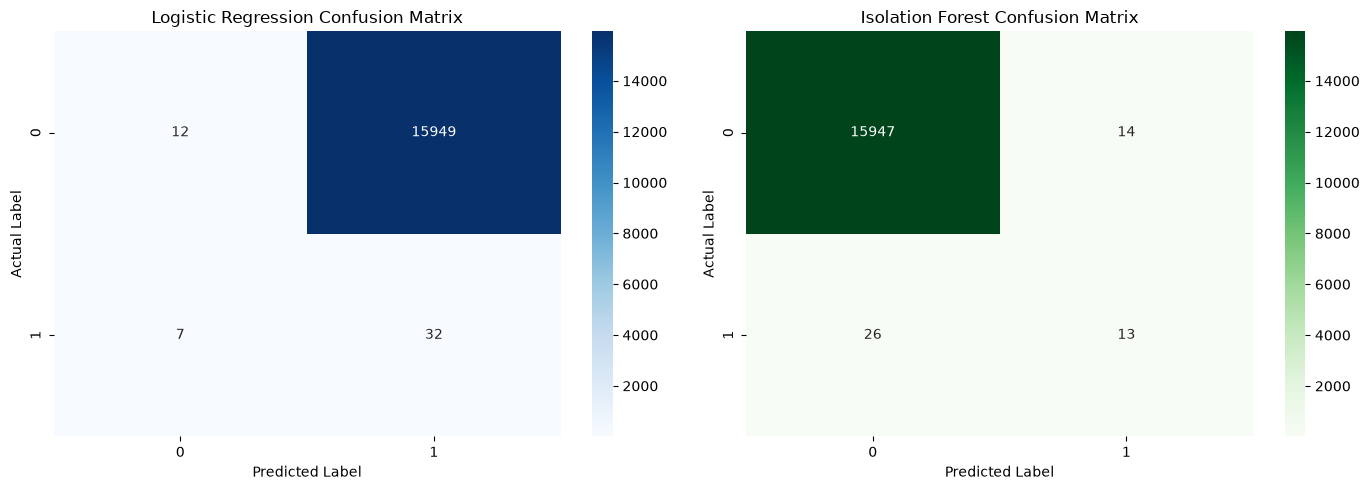

In [211]:
# Plot confusion matrices for both classifiers.

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_logistic = confusion_matrix(y_test, logistic_pred)
cm_isolation = confusion_matrix(y_test, isolation_pred)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

sns.heatmap(
    cm_isolation,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)

axes[1].set_title('Isolation Forest Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()


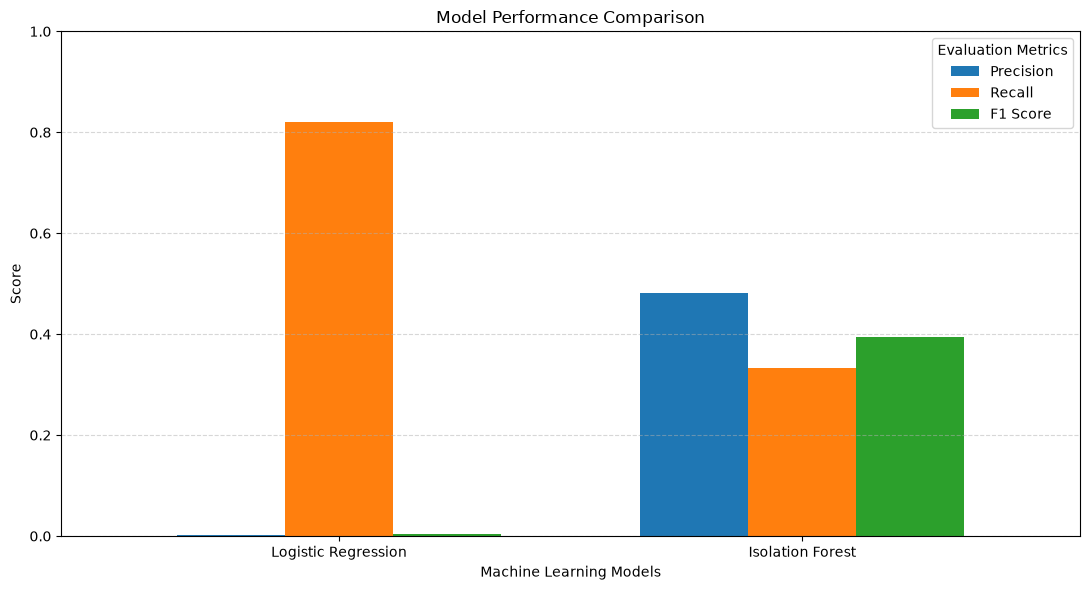

In [212]:
# Plot model performance across all metrics.

comparison_plot = comparison.set_index('Model')

comparison_plot.plot(
    kind='bar',
    figsize=(11, 6),
    width=0.7
)

plt.title('Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


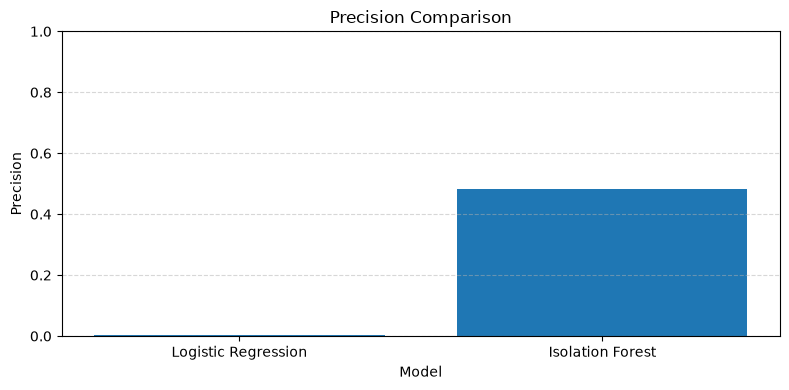

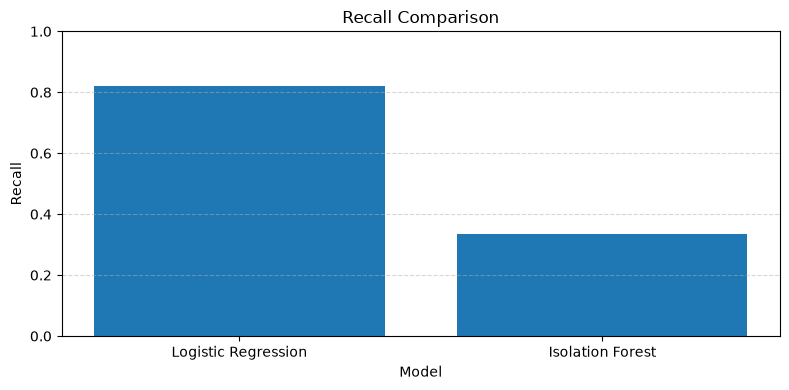

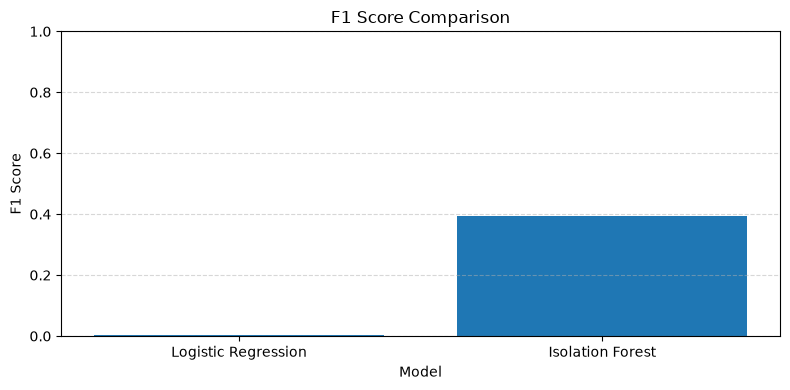

In [213]:
# Plot each model evaluation metric separately.

metrics = ['Precision', 'Recall', 'F1 Score']

for metric in metrics:
    plt.figure(figsize=(8, 4))

    plt.bar(
        comparison['Model'],
        comparison[metric]
    )

    plt.title(f'{metric} Comparison')
    plt.xlabel('Model')
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()


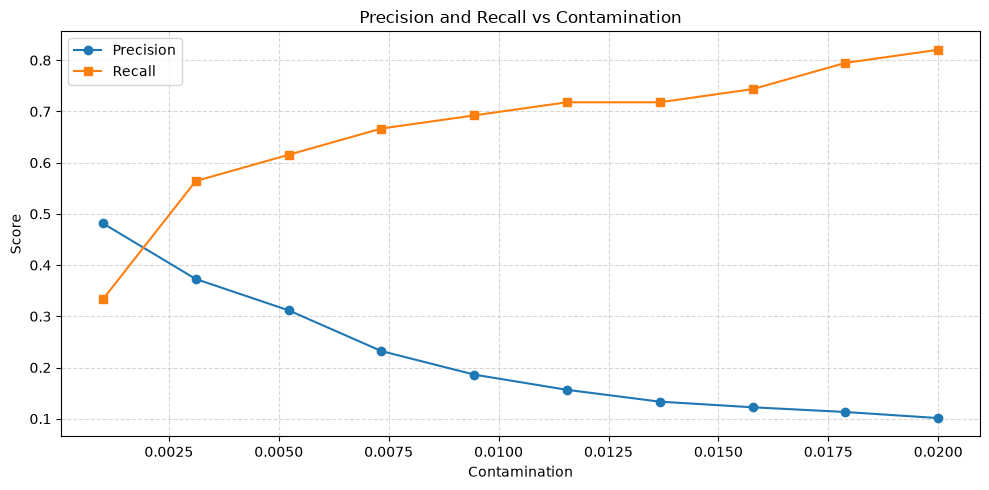

In [215]:
# Measure precision and recall across contamination values.

from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score

# Use the same contamination values tested by GridSearchCV
contamination_values = sorted(
    set(float(x) for x in grid.cv_results_['param_contamination'])
)

precision_values = []
recall_values = []

for contamination in contamination_values:

    model = IsolationForest(
        contamination=contamination,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train)

    raw_predictions = model.predict(X_test)

    predictions = np.where(raw_predictions == -1, 1, 0)

    precision_values.append(
        precision_score(y_test, predictions, zero_division=0)
    )

    recall_values.append(
        recall_score(y_test, predictions, zero_division=0)
    )

plt.figure(figsize=(10, 5))

plt.plot(
    contamination_values,
    precision_values,
    marker='o',
    label='Precision'
)

plt.plot(
    contamination_values,
    recall_values,
    marker='s',
    label='Recall'
)

plt.title('Precision and Recall vs Contamination')
plt.xlabel('Contamination')
plt.ylabel('Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [216]:
# Summarize final fraud detection model results.

print("=" * 55)
print("FINAL CREDIT CARD FRAUD DETECTION EXPERIMENT")
print("=" * 55)

print("\nMODEL COMPARISON:")
print(comparison.to_string(index=False))

best_model = comparison.loc[
    comparison['F1 Score'].idxmax()
]

print("\nBEST PERFORMING MODEL:")
print("Model:", best_model['Model'])
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1 Score:", round(best_model['F1 Score'], 4))

print("\nCONCLUSION:")
print(
    "Isolation Forest achieved a higher F1 score "
    "and precision than Logistic Regression."
)

print(
    "Logistic Regression achieved higher recall, "
    "detecting more of the actual fraud cases."
)

print("\nExperiment completed successfully.")


FINAL CREDIT CARD FRAUD DETECTION EXPERIMENT

MODEL COMPARISON:
              Model  Precision   Recall  F1 Score
Logistic Regression   0.002002 0.820513  0.003995
   Isolation Forest   0.481481 0.333333  0.393939

BEST PERFORMING MODEL:
Model: Isolation Forest
Precision: 0.4815
Recall: 0.3333
F1 Score: 0.3939

CONCLUSION:
Isolation Forest achieved a higher F1 score and precision than Logistic Regression.
Logistic Regression achieved higher recall, detecting more of the actual fraud cases.

Experiment completed successfully.
